In [1]:
import os

tavily_api = os.environ.get("TAVILY_API_KEY")
tavily_api

'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'

In [2]:
from langgraph.graph import StateGraph, END
from typing import TypedDict, Annotated
import operator

from langchain_core.messages import AnyMessage, SystemMessage, HumanMessage, ToolMessage
from langchain_deepseek import ChatDeepSeek
from langchain_tavily.tavily_search import TavilySearch # 搜索工具

In [3]:
tool = TavilySearch(max_results=2)
print(type(tool))
print(tool.name)

<class 'langchain_tavily.tavily_search.TavilySearch'>
tavily_search


In [4]:
class AgentState(TypedDict):
    messages: Annotated[list[AnyMessage], operator.add]

In [5]:
class Agent:
    # 调用模型，检查操作存在，执行操作

    def __init__(self, model, tools, system=""):
        self.system = system
        # 局部变量，仅存在于init内部
        graph = StateGraph(AgentState)

        graph.add_node("llm", self.call_openai) # 创建llm的节点
        graph.add_node("action", self.take_action)

        # 条件边
        graph.add_conditional_edges(
            "llm", # 传入的第一个参数
            self.exists_action, # 决定走向
            {True: "action", False: END} # 表示函数之间的映射方法
        )
        graph.add_edge("action", "llm") # 添加边连接action和llm两个节点，action指向llm
        graph.set_entry_point("llm") # 设置图的入口点
        self.graph = graph.compile()

        # 传入工具列表
        self.tools = {t.name: t for t in tools}
        self.model = model.bind_tools(tools)

    # 创建条件边
    def exists_action(self, state: AgentState):
        result = state['messages'][-1]
        return len(result.tool_calls) > 0 # 判断当前是否还需要函数调用

    # 调用模型
    def call_openai(self,state: AgentState):
        messages = state['messages']
        if self.system:
            messages = [SystemMessage(content=self.system)] + messages
        message = self.model.invoke(messages)
        return {"messages": [message]}

    def take_action(self, state: AgentState):
        tool_calls = state['messages'][-1].tool_calls
        results = [] # 存放调用工具返回的结果
        for t in tool_calls:
            # 通常情况下模型支持并行调用
            print(f"Calling Tools:{t}")
            result = self.tools[t['name']].invoke(t['args'])
            results.append(ToolMessage(tool_call_id=t['id'], name=t['name'], content=result))
        print("Back to the model")
        return {"messages" : results}

In [6]:
prompt = """You are a smart research assistant. Use the search engine to look up information. \
You are allowed to make multiple calls (either together or in sequence).\
Only look up information when you are sure of what you want. \
If you need to look up some information before asking a follow up questi〔on, you are allowed to make \
some of the calls before asking.〕"""

model = ChatDeepSeek(model="deepseek-v4-flash")
abot = Agent(model, [tool], system=prompt)

In [7]:
from IPython.display import Image

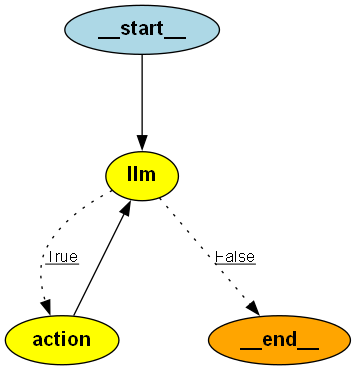

In [8]:
# 打印图表
Image(abot.graph.get_graph().draw_png())

In [9]:
messages = [HumanMessage(content="What is the weather in shanghai?")]
result = abot.graph.invoke({"messages": messages})

Calling Tools:{'name': 'tavily_search', 'args': {'query': 'Shanghai weather today current conditions forecast', 'topic': 'news', 'search_depth': 'basic', 'time_range': 'day'}, 'id': 'call_00_tpFrvQcvyZrfpvavou520836', 'type': 'tool_call'}
Back to the model
Calling Tools:{'name': 'tavily_search', 'args': {'query': 'Shanghai weather forecast today temperature', 'search_depth': 'advanced'}, 'id': 'call_00_QBtX55q7p2K4coBfZfVG2232', 'type': 'tool_call'}
Back to the model


In [23]:
print(result["messages"][-1].content)

Here's the current weather in **Shanghai, China** (as of ~2:30 PM local time, November 3):

## Current Conditions
- **Sky:** Partly cloudy
- **Temperature:** Around **20°C** (feels like 20°C)
- **Wind:** Gusts up to ~29 km/h
- **Humidity:** 61%
- **Dew point:** 12°C
- **Pressure:** 1022 hPa
- **Visibility:** ~9.7 km
- **UV Index:** 2 (Low)
- **Air Quality:** Moderate (AQI ~70)

## Forecast
- **Today:** High **21°C** / Low **17°C** — cloudy with occasional rain showers; ~50% chance of rain. Rain likely develops after midnight (~90% chance).
- **Tomorrow (Wed, Nov 4):** High **19°C** / Low **15°C** — cloudy with periods of rain; near 100% chance, possibly heavy (~25 mm).

**Summary:** Mild and partly cloudy right now, but expect showers to move in later today and into tomorrow, so it's worth carrying an umbrella. Temperatures stay comfortable in the upper teens to low 20s.

Would you like an extended forecast for the rest of the week?


In [24]:
messages = [HumanMessage(content="What is the weather in Sichuan and Shanghai?")]
result = abot.graph.invoke({"messages": messages})

Calling Tools:{'name': 'tavily_search', 'args': {'query': 'current weather Sichuan China Chengdu and Shanghai forecast', 'topic': 'general', 'search_depth': 'advanced'}, 'id': 'call_00_GdJCmUa26jzooy047VmH5280', 'type': 'tool_call'}
Calling Tools:{'name': 'tavily_search', 'args': {'query': '上海 成都 今日天气 预报', 'topic': 'general', 'search_depth': 'advanced'}, 'id': 'call_01_bRvWCjNuuarzHLuGtQjG3732', 'type': 'tool_call'}
Back to the model
Calling Tools:{'name': 'tavily_search', 'args': {'query': '成都天气预报 7天 今天 明天 气温', 'include_domains': ['weather.com.cn'], 'topic': 'general', 'search_depth': 'advanced'}, 'id': 'call_00_0tG7sNtOXb7OjQM265MS2513', 'type': 'tool_call'}
Calling Tools:{'name': 'tavily_search', 'args': {'query': 'Sichuan weather forecast today Chengdu current temperature', 'topic': 'news', 'search_depth': 'advanced', 'time_range': 'day'}, 'id': 'call_01_wI1WzicUvG840P4KK8Cq3865', 'type': 'tool_call'}
Calling Tools:{'name': 'tavily_search', 'args': {'query': 'Shanghai weather forec

In [25]:
print(result["messages"][-1].content)

**As of November 3, 2026:**

### Sichuan
Sichuan is a large province with varied weather, so conditions differ by region. For **Chengdu**, the main city:

- **Overcast**
- **14–19°C**
- Humidity around **76%**
- Light northeasterly wind

Across the **Sichuan Basin** today: mostly overcast with some clouds and scattered showers or light rain. Lows **12–15°C**; highs **16–17°C** in the northeast and **18–20°C** elsewhere. The western Sichuan Plateau and Panxi region are mostly cloudy to sunny, with isolated showers.

### Shanghai
- **14–20°C**
- Mostly cloudy during the day, turning cloudy with **short periods of light rain** toward evening
- Rain continues into Wednesday night and may become heavy at times
- Thursday: rain gradually stops, becoming cloudy and windy

**Bottom line:** Chengdu is cool and overcast; Shanghai is milder but wetter, especially from this evening into Wednesday night.


In [26]:
query = "Who won the super bowl in 2024?What is the GDP of that state?"
messages = [HumanMessage(content=query)]
result = abot.graph.invoke({"messages": messages})

Calling Tools:{'name': 'tavily_search', 'args': {'query': 'Missouri GDP 2024 current dollars', 'search_depth': 'advanced'}, 'id': 'call_00_u6jnW2HAdejwGyTf36MY4110', 'type': 'tool_call'}
Back to the model
Calling Tools:{'name': 'tavily_search', 'args': {'query': 'BEA Missouri GDP 2024 current dollars billion', 'search_depth': 'advanced', 'include_domains': ['bea.gov']}, 'id': 'call_00_HkvcWNemcPXuYqk7Q3x56602', 'type': 'tool_call'}
Back to the model
Calling Tools:{'name': 'tavily_search', 'args': {'query': '"Missouri" "2024" GDP "$" billion nominal BEA', 'search_depth': 'advanced'}, 'id': 'call_00_o2iKX8ega6iHUEE5nTzj1045', 'type': 'tool_call'}
Back to the model
Calling Tools:{'name': 'tavily_search', 'args': {'query': 'Missouri GDP 2023 2024 2025 current dollars table', 'search_depth': 'advanced'}, 'id': 'call_00_XVKF52ENL0ohFoYzYhqy6124', 'type': 'tool_call'}
Back to the model


In [27]:
print(result["messages"][-1].content)
# 第二个查询依赖于第一个查询的结果，即串行查询

The **Kansas City Chiefs** won **Super Bowl LVIII** in February 2024, defeating the San Francisco 49ers **25–22 in overtime**.

The Chiefs are based in **Kansas City, Missouri**, so the state is **Missouri**.

- **Missouri nominal GDP (2024):** about **$455.8 billion**
- **Latest estimate (2025):** about **$475.4 billion**

Sources: BEA data via [FRED](https://fred.stlouisfed.org/series/MONGSP).
